In [72]:
import numpy as np
import pandas as pd
import xsim
import xtools as xt
import matplotlib.pyplot as plt
from pyqubo import Array, Constraint
from openjij import SQASampler, SASampler
from typing import Callable, Dict, List
from numpy.typing import NDArray
from collections import defaultdict

from atm.flight.generator import ScenarioGenerator
from atm.optimizer.objective import get_obj_single_runway, calc_assign_time
from atm.separation import recat, faa
from atm.optimizer.problem import Problem
# from atm.utility.seeding import seeding, MAX_SEED_VALUE

In [3]:
cf = xt.Config(dict(
    num=10,
    scenario=dict(
        interval=60,
        window=200,
        mode="mix",
        standard="recat",
        seed=0,
    ),
    penalty_coef=10,
))
sep = recat.TBS if cf.scenario.standard == "recat" else faa.TBS

In [11]:
class Solution:
    
    def __init__(self, x, cost):
        self._x = np.asarray(x)
        self._cost = cost
    
    def __str__(self):
        return f"x={self._x}, cost={self._cost}"
    
    def __repr__(self):
        return self.__str__()
    
    @property
    def x(self):
        return self._x.copy().squeeze()
    
    @property
    def e(self):
        return self._cost
    
    def __eq__(self, other):
        is_same_x = self.x == other.x
        is_same_e = self.e == other.e
        return is_same_x and is_same_e
    
    def __gt__(self, other):
        return self.e > other.e
    
    def __ge__(self, other):
        return self.e >= other.e
    
    def __lt__(self, other):
        return self.e < other.e
    
    def __le__(self, other):
        return self.e <= other.e

In [12]:
MAX_SEED_VALUE = 2 ** 16

def seeding(seed: int = None):
    if seed is None:
        seed = np.random.randint(2**16)
    rng = np.random.default_rng(seed)
    return rng, seed

In [13]:
class Sampler:
    
    REG = 1e-8
    
    def __init__(self, temp: float = 1., seed: int = None):
        self.rs, self._seed = seeding(seed)
        self.T = temp
        
    def seed(self, seed: int = None):
        self.rs, self._seed = seeding(seed)
    
    def sample(self, sol: Solution, **kwargs):
        raise NotImplementedError
    
    def calc_acceptance_prob(self, sc: Solution, sp: Solution, **kwargs):
        raise NotImplementedError
    
    def exp(self, sol: Solution):
        return np.exp(-1 * sol.e / self.T)

In [14]:
class RandomSwapSampler(Sampler):
    
    def sample(self, sol: Solution, **kwargs):
        idx1, idx2 = self.rs.choice(len(sol.x), size=2, replace=False)
        xp = sol.x
        xp[idx1] = sol.x[idx2]
        xp[idx2] = sol.x[idx1]
        return xp
    
    def calc_acceptance_prob(self, sc: Solution, sp: Solution, **kwargs):
        if sc.e >= sp.e:
            return 1.
        ef = self.exp
        return ef(sp) / (ef(sc) + self.REG)

## Character assignment

- index of vols in the queue: $j \in J$
- vols in the queue: $v_j \in V$
- pair index of que the vol $v_j$ belongs: $k \in K$
- pair que the vol $v_j$ belongs: $p_k \in P$
- paired vol of vol $v_j$: $w_j \in V$

How to 

In [110]:
class PairSwapSampler(Sampler):
    
    def __init__(self, problem: Problem, temp: float = 1., seed: int = None):
        super().__init__(temp, seed)
        self.prob = problem
        
        self.sampler = SASampler()
    
    def sample(self, sol: Solution, **kwargs):
        step = kwargs.get("step", 1)
        S = self.prob.sep
        vs, ps, ws = self.make_pairs(sol, step)
        Nk = len(vs) // 2
        
        qubo = np.zeros((Nk, Nk))
        for i, j, vi, wi, vj, wj in zip(ps[:-1], ps[1:], vs[:-1], ws[:-1], vs[1:], ws[1:]):
            Svivj = S(vi, vj)
            A = S(wi, vj) - Svivj
            B = S(vi, wj) - Svivj
            C = S(wi, wj) - Svivj
            D = C - A - B

            qubo[i, i] += A
            qubo[j, j] += B
            qubo[i, j] += D

        sol = self.sampler.sample_qubo(qubo)
        sol = sol.first
        xdict = sol.sample
        xp = np.array([xdict[i] for i in range(Nk)])
        return xp
    
    def make_pairs(self, sol: Solution, step: int):
        prob = self.prob
        vols = self.prob.vols
        
        # prepare current queue que est given as parameter
        given_queue = [vols[i] for i in sol.x]
        # calc num of shift to achieve shifted pairing
        num_shift = (step + 1) % 2
        
        # make pairs
        num_of_pairs = Nk = (prob.size - num_shift) // 2
        num_of_paired_elements = num_of_pairs * 2
        
        # assign pairs
        ks = np.arange(num_of_paired_elements).astype(int)
        print("ks:", ks)
        # pair map
        ps = np.vstack([np.arange(Nk),] * 2).T.flatten()
        print("ps:", ps)
        # vol list
        # retrieve vols from queue considering shift
        vs = given_queue[num_shift:num_shift+num_of_paired_elements]
        print("vs:", [v.code for v in vs])
        # paired vol list
        ws = np.zeros_like(vs)
        for i, j in ks.reshape((-1, 2)):
            ws[i] = vs[j]
            ws[j] = vs[i]
        print("ws:", [w.code for w in ws])
        return vs, ps , ws
        
        

problem = Problem(cf)
sampler = PairSwapSampler(problem)
x0 = np.arange(problem.size)
e0 = problem.evaluate(x0)
sampler.sample(Solution(x0, e0), step=1)

ks: [0 1 2 3 4 5 6 7 8 9]
ps: [0 0 1 1 2 2 3 3 4 4]
vs: ['VOL0001', 'VOL0002', 'VOL0003', 'VOL0004', 'VOL0005', 'VOL0006', 'VOL0007', 'VOL0008', 'VOL0009', 'VOL0010']
ws: ['VOL0002', 'VOL0001', 'VOL0004', 'VOL0003', 'VOL0006', 'VOL0005', 'VOL0008', 'VOL0007', 'VOL0010', 'VOL0009']


array([1, 1, 0, 1, 0], dtype=int8)

In [16]:
class Optimizer:
    
    def __init__(
            self,
            seed: int = None,
    ):
        self.prob: Problem = None
        self.samp: Sampler = None
        
        # experiments
        # logging
        self.logger: xsim.Logger = None
        # random
        self.rs = None
        self.seed = None
    
    def initialize(self):
        nx = self.prob.size
        xc = np.arange(nx)
        ec = self.prob.evaluate(xc)
        sc = Solution(xc, ec)
        sb = sc
        
        self.logger = xsim.Logger()
        return sc, sb
    
    def log(self, sc: Solution, sb: Solution, step: int = None):
        if step is None:
            step = len(self.logger)
        self.logger.store(step=step, xc=sc.x, ec=sc.e, xb=sb.x, eb=sb.e).flush()
    
    def optimize(
            self,
            problem: Problem,
            sampler: Sampler,
            max_iter: int,
            seed: int = None,
    ):
        # receive prob and sampler
        self.rs, self.seed = seeding(seed)
        sampler.seed(self.rs.integers(MAX_SEED_VALUE))
        prob = self.prob = problem
        samp = self.samp = sampler
        
        # initialize
        sc, sb = self.initialize()
        self.log(sc, sb)
        
        # main loop
        for step in range(1, max_iter + 1):
            xp = samp.sample(sc, step=step)
            ep = prob.evaluate(xp)
            sp = Solution(xp, ep)
            
            # stochastic accepting
            r = samp.calc_acceptance_prob(sc, sp, step=step)
            if r > self.rs.random():
                sc = sp
            
            # update best
            if sb >= sc:
                sb = sc
            
            self.log(sc, sb, step=step)

In [98]:
optimizer = Optimizer()
optimizer.optimize(
    Problem(cf), RandomSwapSampler(), max_iter=300, seed=0
)

<AxesSubplot:xlabel='step'>

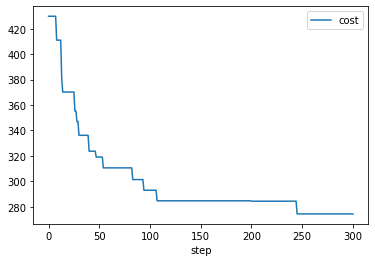

In [99]:
ret = xsim.Retriever(optimizer.logger)
res = pd.DataFrame(dict(
    step=ret.step(),
    cost=ret.eb()
))
res.plot(x="step", y="cost")